# Layer-dependent QSVT comb: bright eigenvalues only

Copy of: `1.Bright_filtering.ipynb` . 

Changes: p(4)=0 . this notebook always supresses the $\lambda = 4$ even if this is a bright eigenvalue of the true track. THis is done because $\lambda = 4$ is dominated by isolated segments.

In [10]:
from pathlib import Path
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Markdown

# Always import this checkout, even when another checkout is installed.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'src/lhcb_velo_toy').is_dir()
            or (p / 'LHCb_VeLo_Toy_Model/src/lhcb_velo_toy').is_dir())
if not (ROOT / 'src/lhcb_velo_toy').is_dir():
    ROOT = ROOT / 'LHCb_VeLo_Toy_Model'
sys.path.insert(0, str(ROOT / 'src'))

from lhcb_velo_toy.generation import PlaneGeometry, StateEventGenerator
from lhcb_velo_toy.solvers import SimpleHamiltonianFast, get_tracks
from lhcb_velo_toy.solvers.quantum import QSVT, spectral_bounds
from lhcb_velo_toy.analysis import compute_epsilon, metrics_at_wp
from lhcb_velo_toy.analysis.segment_metrics import segment_truth_mask
from lhcb_velo_toy.analysis.working_points import rescale_to_signal, threshold_for
from lhcb_velo_toy.analysis.plotting.event_display import plot_reco_vs_truth

plt.rcParams['figure.dpi'] = 110
print('Using', ROOT)

Using c:\Users\joseh\BTR\LHCb_VeLo_Toy_Model


In [11]:
# Edit these controls
N_LAYERS = 6
LAYER_SCAN = [5, 6, 7, 8, 9, 10]
N_TRACKS = 400
DEGREE = 80
HALF_WIDTH = 0.18        # thesis default; larger L may need narrower passes / higher degree
GAMMA, DELTA = 3.0, 1.0
DZ = 33.0               # mm; held fixed as layers change
MEASUREMENT_ERROR = 0.01 # mm; matches the original activation spectra
COLLISION_NOISE = 1e-4  # matches the original activation spectra
PHI_MIN, PHI_MAX = -0.2, 0.2     # radians: x-z angle; widen to -0.3, 0.3
THETA_MIN, THETA_MAX = -0.2, 0.2 # radians: y-z angle; widen to -0.3, 0.3
SEED = 202
TARGET_EFF = 0.95       # truth-calibrated diagnostic, as in the thesis
VERIFY_BACKENDS = True # component eigensolver check on the selected event
RECONSTRUCT_TRACKS = True

assert isinstance(N_LAYERS, int) and N_LAYERS >= 3
assert N_TRACKS >= 1 and DEGREE >= 1 and HALF_WIDTH > 0
assert GAMMA + DELTA > 2 and DELTA > 0
assert 0 < TARGET_EFF <= 1
S = GAMMA + DELTA
# Restart the kernel and Run All after changing angles to regenerate events and tracks.
# Wider angles can move hits outside the detector, leaving shorter tracks.
assert -np.pi/2 < PHI_MIN < PHI_MAX < np.pi/2
assert -np.pi/2 < THETA_MIN < THETA_MAX < np.pi/2
BRIGHT_TOL = 1e-10 # same overlap tolerance as structure_eigenvalue_modes
REJECT_EIGENVALUE = 4.0 # fixed rejection, independent of brightness or diagonal shift
NOTCH_WIDTH = HALF_WIDTH # Gaussian notch width in eigenvalue units

In [12]:
def path_lines(n_layers, s=S):
    if not isinstance(n_layers, (int, np.integer)) or n_layers < 2:
        raise ValueError('n_layers must be an integer >= 2')
    return s - 2 * np.cos(np.arange(1, n_layers) * np.pi / n_layers)


def path_modes(n_layers, s=S):
    # Same overlap calculation and tolerance as structure_eigenvalue_modes.
    eigenvalues = path_lines(n_layers, s)
    m = n_layers - 1
    block = s * np.eye(m) - np.eye(m, k=1) - np.eye(m, k=-1)
    measured, vectors = np.linalg.eigh(block)
    overlap = np.abs(vectors.T @ (np.ones(m) / np.sqrt(m)))
    bright = overlap > BRIGHT_TOL
    np.testing.assert_allclose(measured, eigenvalues, atol=1e-12)
    np.testing.assert_array_equal(bright, np.arange(1, n_layers) % 2 == 1)
    np.testing.assert_allclose(np.sum(overlap**2), 1, atol=1e-12)
    return eigenvalues, bright, overlap**2


def bright_path_lines(n_layers, s=S):
    eigenvalues, bright, _ = path_modes(n_layers, s)
    return eigenvalues[bright]


def comb_target(lam, lines, hw=HALF_WIDTH):
    lam = np.asarray(lam, dtype=float)
    lines = np.asarray(lines, dtype=float)
    if not lines.size:
        return np.zeros_like(lam)
    passes = np.max(np.exp(-((lam[..., None] - lines) / hw)**2), axis=-1)
    inverse = passes / np.clip(lam, max(float(lines.min()), 1e-6), None)
    notch = -np.expm1(-((lam - REJECT_EIGENVALUE) / NOTCH_WIDTH)**2)
    return inverse * notch


def fit_reject_four(domain, lines, degree=DEGREE):
    from numpy.polynomial import chebyshev as cheb
    if degree < 1:
        raise ValueError('A nonzero polynomial with a mandatory root needs degree >= 1')
    if len(lines) == 0:
        raise ValueError('No bright pass lines remain after rejecting eigenvalue 4')
    lo, hi = map(float, domain)
    lam = np.linspace(lo, hi, max(6000, 50 * (degree + 1)))
    x = (2 * lam - lo - hi) / (hi - lo)
    x0 = (2 * REJECT_EIGENVALUE - lo - hi) / (hi - lo)
    # Parameterize p(x)=(x-x0)r(x), so least squares cannot reintroduce p(4).
    basis = (x - x0)[:, None] * cheb.chebvander(x, degree - 1)
    coef, *_ = np.linalg.lstsq(basis, comb_target(lam, lines), rcond=None)
    factor = cheb.Chebyshev([-x0, 1.0], domain=[lo, hi])
    poly = factor * cheb.Chebyshev(coef, domain=[lo, hi])
    # Bound the response over the entire domain using endpoints and stationary points.
    roots = poly.deriv().roots()
    stationary = roots.real[(np.abs(roots.imag) < 1e-9) & (roots.real >= lo) & (roots.real <= hi)]
    peak = np.max(np.abs(poly(np.r_[lo, hi, stationary, lam])))
    if peak > 0.95:
        poly = poly * (0.95 / peak)
    assert abs(float(poly(REJECT_EIGENVALUE))) < 1e-12
    assert poly.degree() <= degree
    return poly


def make_event(n_layers, seed=SEED):
    geometry = PlaneGeometry(
        module_id=list(range(n_layers)), lx=[50.0] * n_layers,
        ly=[50.0] * n_layers, z=[100.0 + i * DZ for i in range(n_layers)])
    gen = StateEventGenerator(
        detector_geometry=geometry, events=1, n_particles=[N_TRACKS],
        measurement_error=MEASUREMENT_ERROR, collision_noise=COLLISION_NOISE,
        phi_min=PHI_MIN, phi_max=PHI_MAX,
        theta_min=THETA_MIN, theta_max=THETA_MAX, seed=seed)
    gen.generate_random_primary_vertices({'x': 0, 'y': 0, 'z': 0})
    gen.generate_particles([[{'type': 'pion', 'mass': 139.6, 'q': 1}] * N_TRACKS])
    gen.generate_complete_events()
    return gen


def run_layer(n_layers, seed=SEED):
    gen = make_event(n_layers, seed)
    eps = compute_epsilon(MEASUREMENT_ERROR, COLLISION_NOISE, dz=DZ)
    ham = SimpleHamiltonianFast(epsilon=eps, gamma=GAMMA, delta=DELTA)
    A, b = ham.construct_hamiltonian(gen)
    truth = segment_truth_mask(ham)  # exactly the Hamiltonian's segment ordering
    all_lines, bright_mask, weights = path_modes(n_layers)
    rejected_mask = np.isclose(all_lines, REJECT_EIGENVALUE, atol=1e-10, rtol=0)
    lines = all_lines[bright_mask & ~rejected_mask]
    # Match the existing QSVT design domain, then fit with the mandatory root.
    bounds = spectral_bounds(A)
    span = max(bounds[1] - bounds[0], 1e-12)
    domain = (min(bounds[0] - 0.02 * span, S - 3.8),
              max(bounds[1] + 0.02 * span, S + 3.8))
    poly = fit_reject_four(domain, lines)
    q = QSVT(A, b, poly=poly, spectral_bounds=bounds)
    np.testing.assert_allclose(q.poly(4.0), 0.0, atol=1e-12)
    t0 = time.perf_counter()
    amplitudes, success = q.solve_statevector()
    elapsed = time.perf_counter() - t0
    classical = np.abs(ham.solve_classicaly())
    scaled = rescale_to_signal(amplitudes, classical, threshold=threshold_for(GAMMA, DELTA))
    assert len(truth) == len(amplitudes) == A.shape[0]
    assert np.isfinite(amplitudes).all() and 0 <= success <= 1 + 1e-10
    assert np.isclose(np.linalg.norm(amplitudes), 1)
    return dict(layers=n_layers, gen=gen, ham=ham, A=A, b=b, truth=truth,
                lines=lines, rejected_lines=all_lines[rejected_mask], dark_lines=all_lines[~bright_mask], mode_weights=weights, q=q, amplitudes=amplitudes, scaled=scaled,
                classical=classical, success=success, elapsed=elapsed,
                metrics=metrics_at_wp(scaled, truth, target_eff=TARGET_EFF))

# Independent check of the cosine formula, including the original five-layer case.
for layers in sorted(set([N_LAYERS, *LAYER_SCAN, 5])):
    m = layers - 1
    block = S * np.eye(m) - np.eye(m, k=1) - np.eye(m, k=-1)
    np.testing.assert_allclose(np.linalg.eigvalsh(block), path_lines(layers), atol=1e-12)
for layers in sorted(set([N_LAYERS, *LAYER_SCAN, *range(3, 11)])):
    path_modes(layers)
print('Cosine lines and bright/dark overlap parity verified through 10 layers.')

Cosine lines and bright/dark overlap parity verified through 10 layers.


## Fit the comb for the selected layer count

The green vertical lines are the analytic pass centres. The black curve is the
finite-degree fit; its peaks need not land exactly on the centres. The dashed
curve is the Gaussian inverse target. Degree and width control the fit quality.
Red markers show shorter-path eigenvalues, not a guaranteed false-only spectrum.
A shared eigenvalue cannot simultaneously be passed and rejected.

Only bright complete-track lines receive passes; dark complete-track lines are shown as hollow grey circles.

Eigenvalue 4 is always rejected, including when bright. The red dashed line marks the mandatory zero.

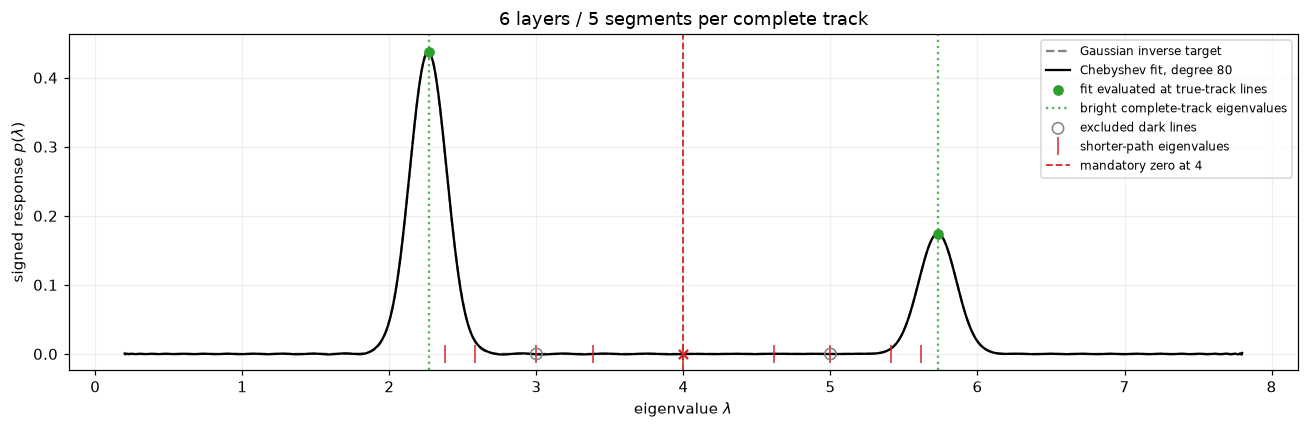

Pass centres: [2.26794919 5.73205081]
Polynomial domain: [0.2 7.8]
Segments: 780400, true: 1951, LCU success: 0.00135149, solve: 1.179 s
Maximum sampled target-fit error: 0.003919
Lines shared with shorter paths: []
Excluded dark lines: [3. 5.]
Mandatory response p(4): 0.0


In [13]:
result = run_layer(N_LAYERS)
q = result['q']
lo, hi = q.poly.domain
lam = np.linspace(lo, hi, 6000)
target = comb_target(lam, result['lines'])
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(lam, target, '--', color='0.5', label='Gaussian inverse target')
ax.plot(lam, q.poly(lam), color='black', label=f'Chebyshev fit, degree {q.degree}')
ax.scatter(result['lines'], q.poly(result['lines']), color='tab:green', zorder=4,
           label='fit evaluated at true-track lines')
for i, line in enumerate(result['lines']):
    ax.axvline(line, color='tab:green', ls=':', alpha=0.8,
               label='bright complete-track eigenvalues' if i == 0 else None)
ax.scatter(result['dark_lines'], np.zeros_like(result['dark_lines']),
           facecolors='none', edgecolors='grey', s=55, zorder=5, label='excluded dark lines')
short_lines = np.unique(np.round(np.concatenate([path_lines(j) for j in range(2, N_LAYERS)]), 12))
ax.plot(short_lines, np.zeros_like(short_lines), '|', color='tab:red', ms=12,
        label='shorter-path eigenvalues')
ax.set(xlabel=r'eigenvalue $\lambda$', ylabel=r'signed response $p(\lambda)$',
       title=f'{N_LAYERS} layers / {N_LAYERS - 1} segments per complete track')
ax.axvline(4.0, color='tab:red', ls='--', lw=1.2, label='mandatory zero at 4')
ax.scatter([4.0], [q.poly(4.0)], color='tab:red', marker='x', zorder=6)
ax.legend(fontsize=8); ax.grid(alpha=0.2); fig.tight_layout(); plt.show()
print('Pass centres:', np.round(result['lines'], 8))
print('Polynomial domain:', q.poly.domain)
print(f"Segments: {len(result['truth'])}, true: {result['truth'].sum()}, "
      f"LCU success: {result['success']:.6g}, solve: {result['elapsed']:.3f} s")
print(f'Maximum sampled target-fit error: {np.max(np.abs(q.poly(lam) - target)):.4g}')
shared = [line for line in result['lines'] if np.any(np.isclose(line, short_lines, atol=1e-10, rtol=0))]
print('Lines shared with shorter paths:', np.round(shared, 8))
print('Excluded dark lines:', np.round(result['dark_lines'], 8))
print('Mandatory response p(4):', float(q.poly(4.0)))
np.testing.assert_allclose(q.poly(4.0), 0.0, atol=1e-12)

In [14]:
if VERIFY_BACKENDS:
    x_eigh, p_eigh = q.solve_eigh()
    np.testing.assert_allclose(x_eigh, result['amplitudes'], atol=1e-9, rtol=1e-8)
    np.testing.assert_allclose(p_eigh, result['success'], atol=1e-10, rtol=1e-8)
    print('Matrix-free recursion and component eigendecomposition agree.')

Matrix-free recursion and component eigendecomposition agree.


## Check bright-only evaluation and compare with all-mode comb

The bright-only filter intentionally differs from the original all-mode P4 comb.
Verify its output by explicitly projecting the uniform input onto the ideal path's
eigenmodes, and compare both designs on the **same simulated event**. The event
comparison is diagnostic; amplitudes need not match because the polynomials differ.


The all-mode reference below is deliberately unmodified, for comparison with the mandatory-zero design.

In [15]:
# Check the actual fitted polynomial against direct spectral evaluation on an ideal path.
m = N_LAYERS - 1
block = S * np.eye(m) - np.eye(m, k=1) - np.eye(m, k=-1)
ideal = QSVT(block, np.ones(m), poly=q.poly,
             spectral_bounds=(path_lines(N_LAYERS)[0], path_lines(N_LAYERS)[-1]),
             spectrum_pad=0.0)
x_ideal, p_ideal = ideal.solve_statevector()
eigenvalues, vectors = np.linalg.eigh(block)
input_vector = np.ones(m) / np.sqrt(m)
y_direct = vectors @ (q.poly(eigenvalues) * (vectors.T @ input_vector)) / ideal.l1
np.testing.assert_allclose(x_ideal, np.abs(y_direct) / np.linalg.norm(y_direct), atol=1e-10)
np.testing.assert_allclose(p_ideal, np.vdot(y_direct, y_direct).real, atol=1e-12)
print('Bright-only polynomial evaluator matches direct ideal-path evaluation.')

all_mode_reference = QSVT.comb(result['A'], result['b'], degree=DEGREE, s=S,
    spectral_bounds=spectral_bounds(result['A']),
    design_kwargs={'lines': tuple(path_lines(N_LAYERS)), 'hw': HALF_WIDTH})
x_all, p_all = all_mode_reference.solve_statevector()
scaled_all = rescale_to_signal(x_all, result['classical'], threshold=threshold_for(GAMMA, DELTA))
print(f'Bright-only passes: {len(result["lines"])}; all-mode passes: {N_LAYERS - 1}')
print(f'LCU success, bright only: {result["success"]:.6g}; all modes: {p_all:.6g}')
print('Max scaled amplitude difference on the same event:', np.max(np.abs(result['scaled'] - scaled_all)))


Bright-only polynomial evaluator matches direct ideal-path evaluation.
Bright-only passes: 2; all-mode passes: 5
LCU success, bright only: 0.00135149; all modes: 0.131012
Max scaled amplitude difference on the same event: 0.3434307753526141


## Segment activation spectra: green = true, red = incorrect

Both panels are histograms: **x = amplitude on the classical signal scale;
y = number of segments (log scale)**, matching the original notebook's activation
spectra. Classical and QSVT use the same bins. QSVT uses the original
`rescale_to_signal` convention, one global rescaling rather than unit-norm amplitudes.
Colours come from simulated track IDs, independently of predicted activation.
The dashed line is this event's truth-calibrated efficiency threshold; the grey
dotted line is the original fixed-cut diagnostic.

Generation settings are copied unchanged from the variable-layer notebook.
The control is `../quantum_qsvt_end_to_end - kopie.ipynb`. This notebook changes
only which ideal complete-track eigenvalues receive comb passes.


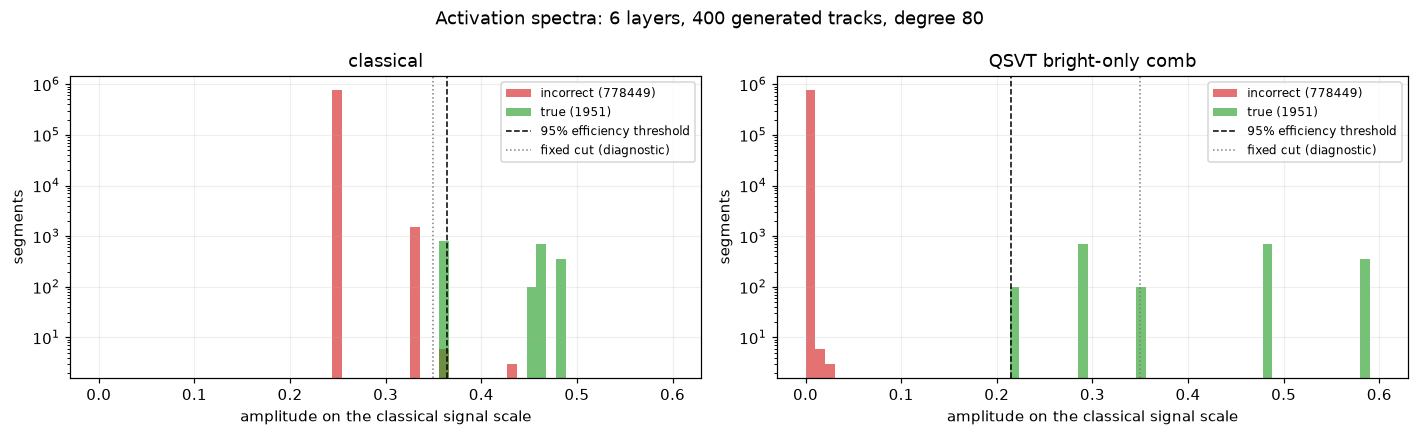

| solver | efficiency | false rate | threshold |
|---|---|---|---|
| classical | 1.0000 | 0.0015 | 0.363633 |
| layer-dependent QSVT comb | 1.0000 | 0.0000 | 0.214749 |


In [16]:
def activation_histogram(ax, x, truth, bins, tau, title):
    for mask, color, label in ((~truth, 'tab:red', 'incorrect'),
                               (truth, 'tab:green', 'true')):
        ax.hist(x[mask], bins=bins, color=color, alpha=0.65,
                label=f'{label} ({mask.sum()})', log=True)
    ax.axvline(tau, color='black', ls='--', lw=1,
               label=f'{TARGET_EFF:.0%} efficiency threshold')
    ax.axvline(threshold_for(GAMMA, DELTA), color='grey', ls=':', lw=1,
               label='fixed cut (diagnostic)')
    ax.set(title=title, xlabel='amplitude on the classical signal scale',
           ylabel='segments')
    ax.legend(fontsize=8); ax.grid(alpha=0.2)


def plot_activations(r):
    bins = np.linspace(0, max(0.6, r['classical'].max() * 1.02,
                             r['scaled'].max() * 1.02), 60)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
    for ax, key, name in zip(axes, ('classical', 'scaled'), ('classical', 'QSVT bright-only comb')):
        met = metrics_at_wp(r[key], r['truth'], target_eff=TARGET_EFF)
        activation_histogram(ax, r[key], r['truth'], bins, met['tau_wp'], name)
    fig.suptitle(f"Activation spectra: {r['layers']} layers, {N_TRACKS} generated tracks, degree {DEGREE}")
    fig.tight_layout(); plt.show()

plot_activations(result)
table = '| solver | efficiency | false rate | threshold |\n|---|---|---|---|\n'
for name, x in [('classical', result['classical']), ('layer-dependent QSVT comb', result['scaled'])]:
    met = metrics_at_wp(x, result['truth'], target_eff=TARGET_EFF)
    table += (f"| {name} | {met['segment_efficiency']:.4f} | {met['segment_false_rate']:.4f} | "
              f"{met['tau_wp']:.6g} |\n")
display(Markdown(table))


## Vary the number of layers

Each row fits a new comb using **only the bright modes for that layer count**.
Generation settings stay fixed. Odd k are selected in the minus-cosine convention;
using a plus sign reverses the ordering and requires changing the parity rule.
The overlap check avoids that ambiguity. For even L, the mode at $s$ is bright
only when L/2 is odd; for L divisible by four it is dark and is omitted.
Shared bright eigenvalues still cannot distinguish true and false structures.


The rejection at eigenvalue 4 overrides brightness at every layer count. Each fit asserts p(4) = 0 to floating-point tolerance.

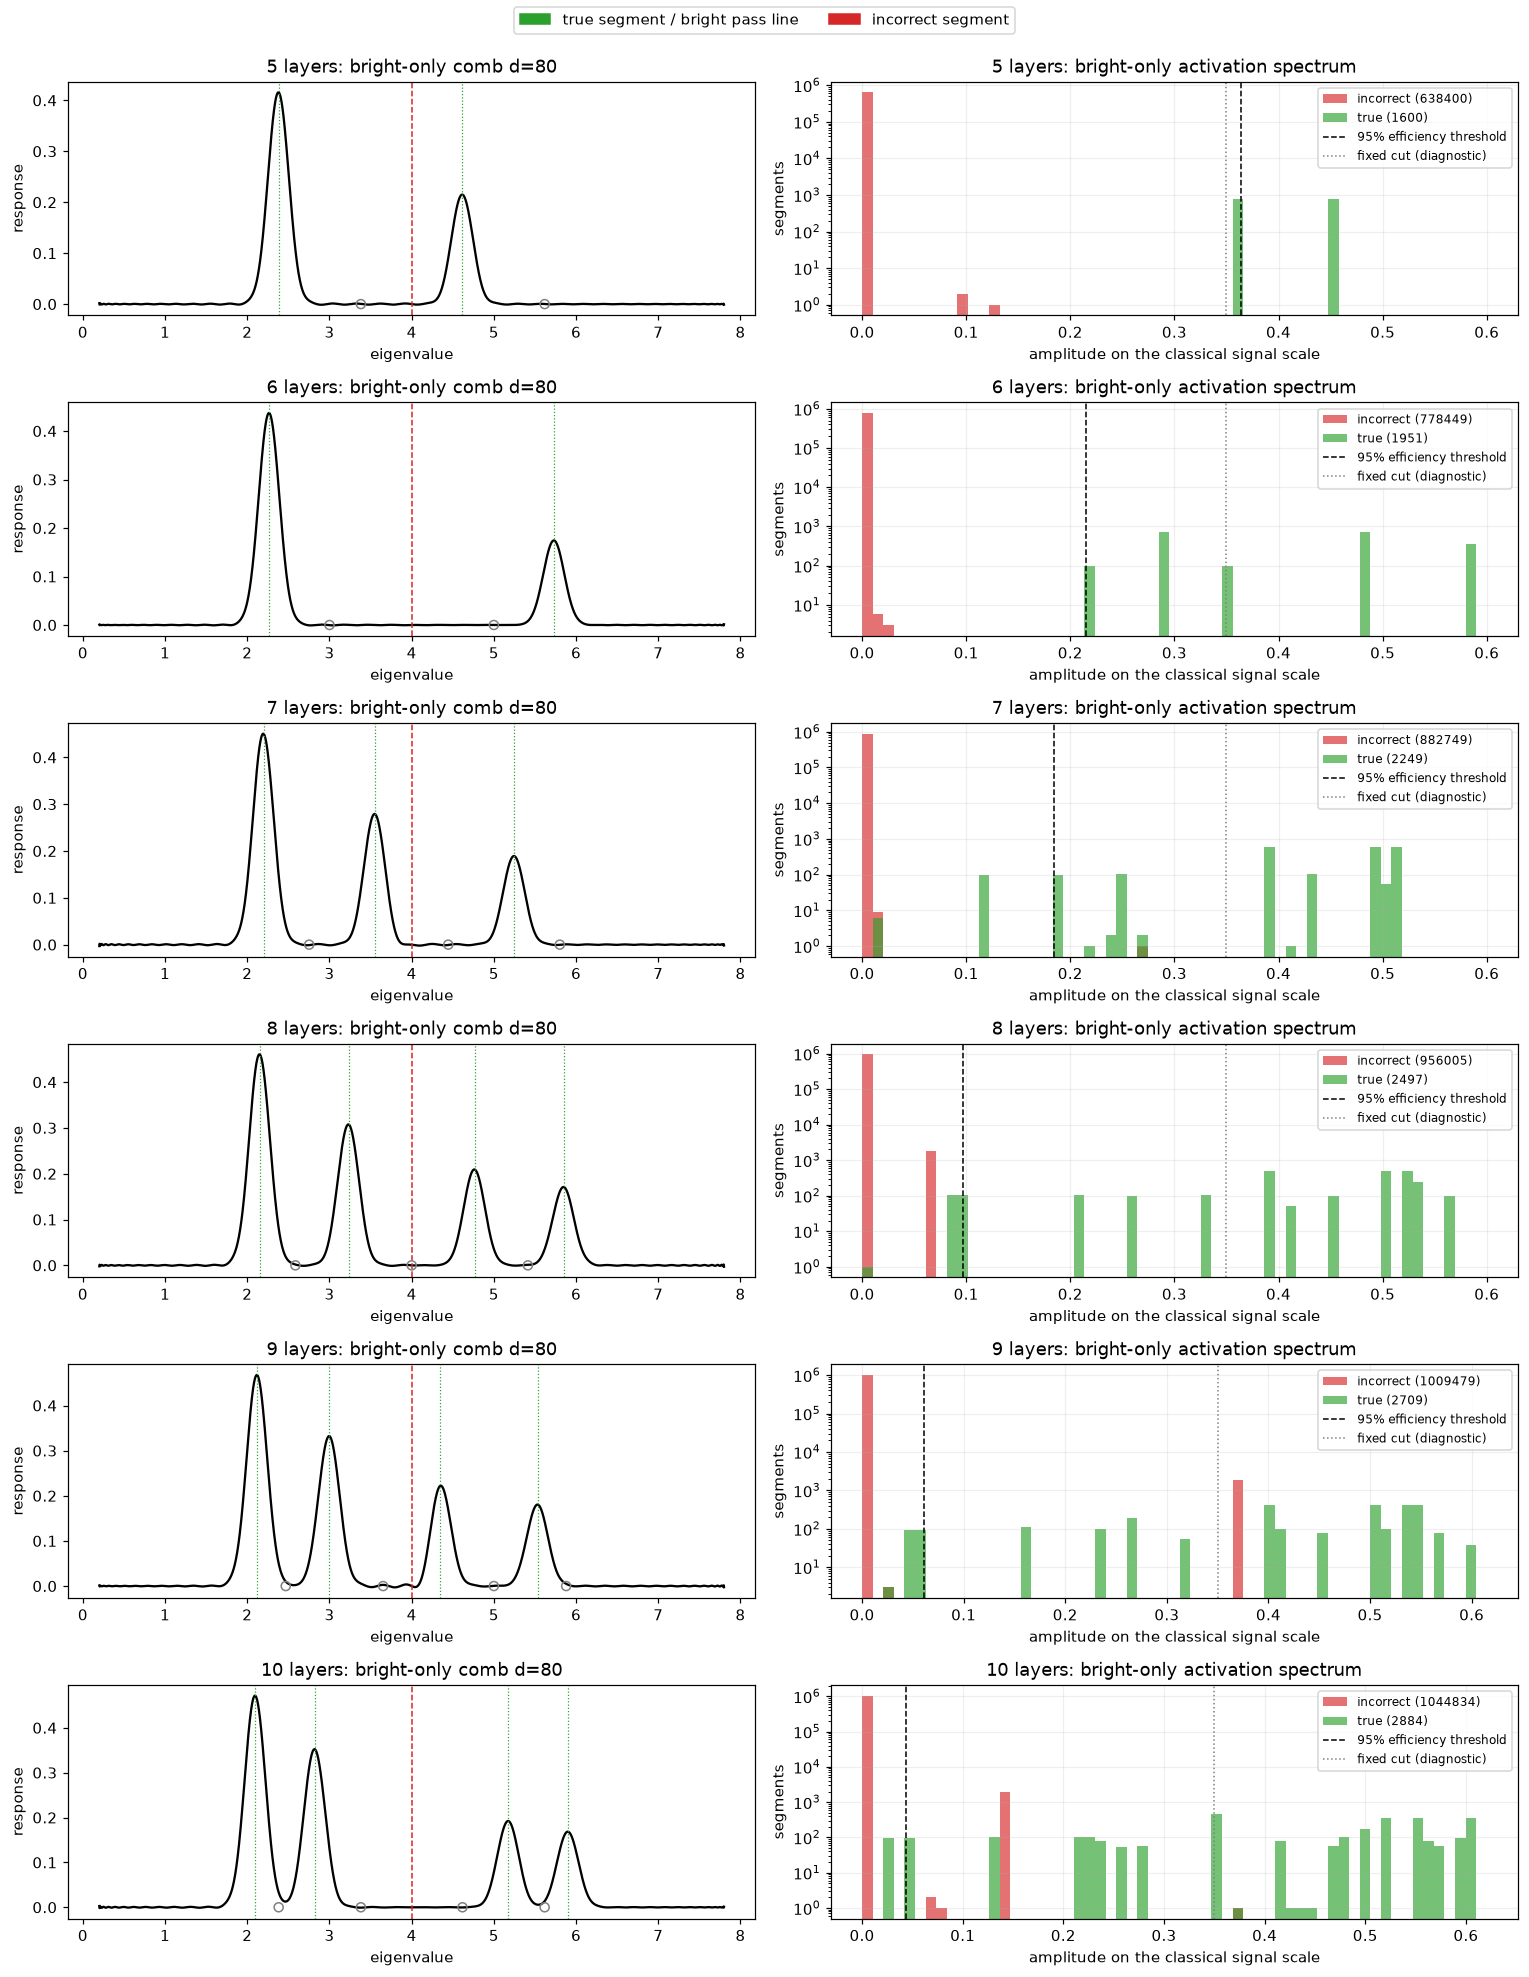

| layers | segments | true | bright eigenvalue lines | efficiency | false rate | LCU success |
|---|---|---|---|---|---|---|
| 5 | 640000 | 1600 | 2.382, 4.618 | 1.0000 | 0.0000 |0.0012824 | 
| 6 | 780400 | 1951 | 2.268, 5.732 | 1.0000 | 0.0000 |0.0013515 | 
| 7 | 884998 | 2249 | 2.198, 3.555, 5.247 | 0.9538 | 0.0005 |0.00098392 | 
| 8 | 958502 | 2497 | 2.152, 3.235, 4.765, 5.848 | 0.9588 | 0.0000 |0.0010553 | 
| 9 | 1012188 | 2709 | 2.121, 3.000, 4.347, 5.532 | 0.9635 | 0.4192 |0.0011668 | 
| 10 | 1047718 | 2884 | 2.098, 2.824, 5.176, 5.902 | 0.9660 | 0.4150 |0.00099468 | 


In [17]:
layer_results = {N_LAYERS: result}
for layers in LAYER_SCAN:
    if layers not in layer_results:
        layer_results[layers] = run_layer(layers)

table = '| layers | segments | true | bright eigenvalue lines | efficiency | false rate | LCU success |\n|---|---|---|---|---|---|---|\n'
fig, axes = plt.subplots(len(LAYER_SCAN), 2, figsize=(14, 3 * len(LAYER_SCAN)), squeeze=False)
for row, layers in enumerate(LAYER_SCAN):
    r = layer_results[layers]
    ax, act = axes[row]
    grid = np.linspace(*r['q'].poly.domain, 3000)
    ax.plot(grid, r['q'].poly(grid), color='black')
    for line in r['lines']:
        ax.axvline(line, color='tab:green', ls=':', lw=0.8)
    ax.scatter(r['dark_lines'], np.zeros_like(r['dark_lines']),
               facecolors='none', edgecolors='grey', s=35, zorder=4)
    ax.axvline(4.0, color='tab:red', ls='--', lw=1)
    np.testing.assert_allclose(r['q'].poly(4.0), 0.0, atol=1e-12)
    ax.set(title=f'{layers} layers: bright-only comb d={DEGREE}', xlabel='eigenvalue', ylabel='response')
    bins = np.linspace(0, max(0.6, r['scaled'].max() * 1.02), 60)
    activation_histogram(act, r['scaled'], r['truth'], bins,
                         r['metrics']['tau_wp'], f'{layers} layers: bright-only activation spectrum')
    met = r['metrics']
    table += (f"| {layers} | {len(r['truth'])} | {r['truth'].sum()} | "
              f"{', '.join(f'{v:.3f}' for v in r['lines'])} | "
              f"{met['segment_efficiency']:.4f} | {met['segment_false_rate']:.4f} |{r['success']:.5g} | \n")
fig.legend(handles=[Patch(color='tab:green', label='true segment / bright pass line'),
                    Patch(color='tab:red', label='incorrect segment')], loc='upper center', ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.98)); plt.show()
display(Markdown(table))

## Reconstruct tracks from the selected layer count

Uses the same track finder and event display as the original notebook, with the
selected QSVT solution and its diagnostic working point. With noise, a high
efficiency target may admit many false segments; inspect the activation plot and
false rate when choosing a target.

Reconstructed tracks: 400


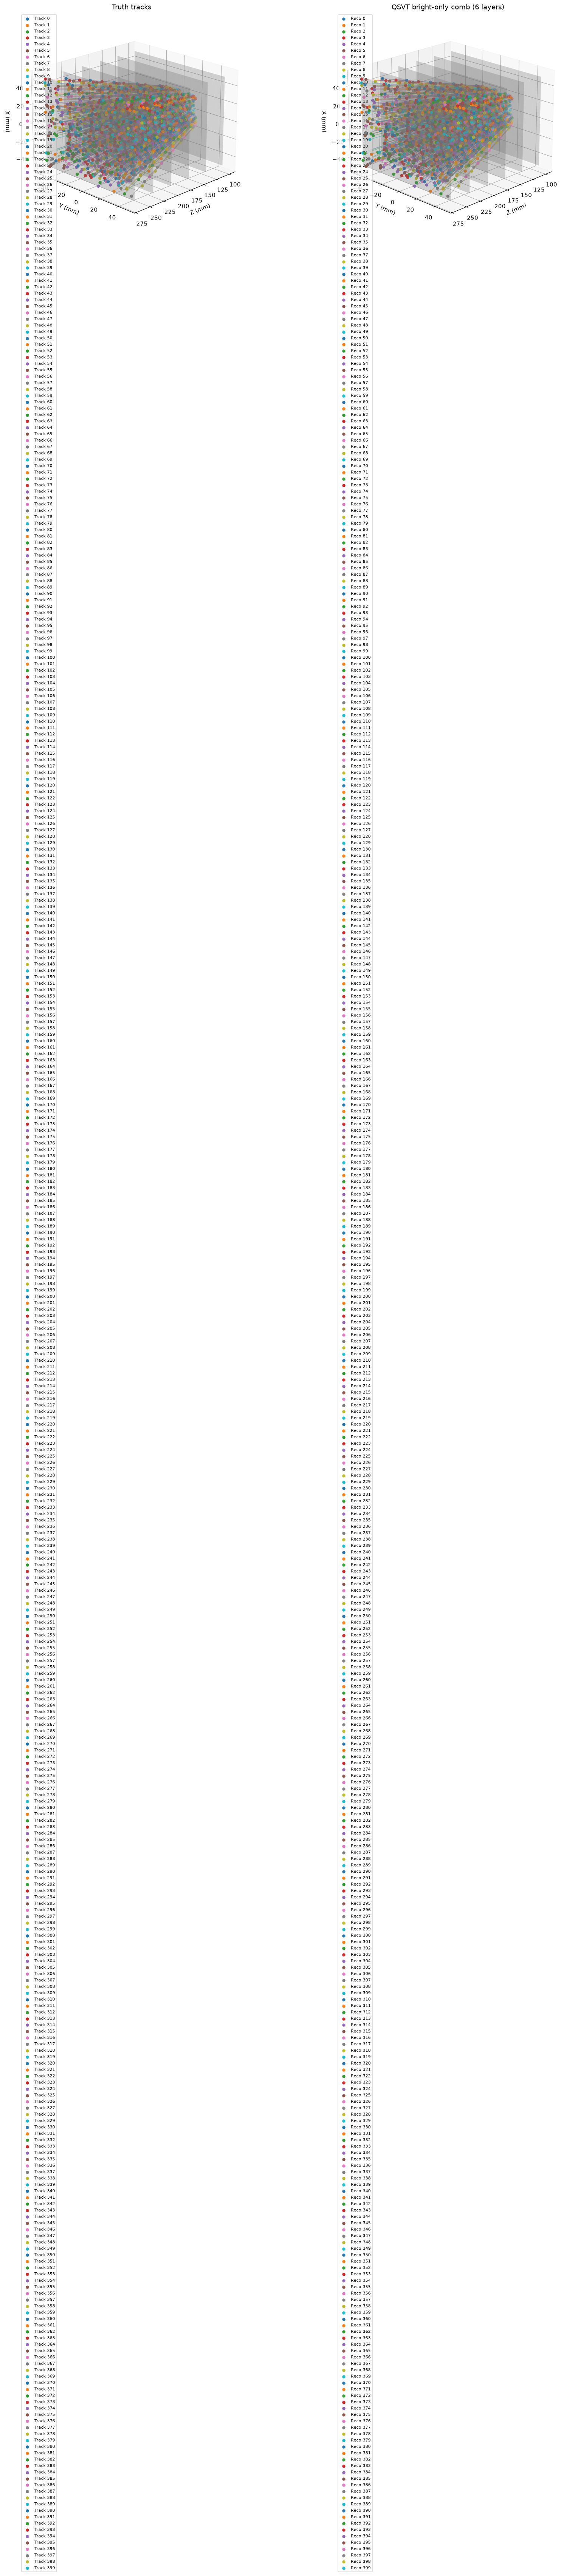

In [18]:
if RECONSTRUCT_TRACKS:
    reconstructed = get_tracks(result['ham'], result['scaled'], result['gen'],
                               threshold=result['metrics']['tau_wp'])
    print(f'Reconstructed tracks: {len(reconstructed)}')
    if reconstructed:
        plot_reco_vs_truth(result['gen'].true_event, reconstructed,
                           title_truth='Truth tracks',
                           title_reco=f'QSVT bright-only comb ({N_LAYERS} layers)')
        plt.show()